In [ ]:
# ============================================================
# CELL 1 — UPLOAD DATASET
# ============================================================

from google.colab import files
import os

print("==========================================")
print("   SICKLE CELL DATASET UPLOAD")
print("==========================================")
print()
print("Upload: Dataset_SickleCell.zip")
print()

uploaded = files.upload()

# Find the uploaded ZIP automatically
zip_files = [
    filename
    for filename in uploaded.keys()
    if filename.lower().endswith(".zip")
]

if len(zip_files) == 0:
    raise FileNotFoundError(
        "❌ No ZIP file found. Please upload Dataset_SickleCell.zip"
    )

DATASET_ZIP = os.path.join("/content", zip_files[0])

print()
print("✅ DATASET UPLOADED SUCCESSFULLY")
print("------------------------------------------")
print("File:", DATASET_ZIP)
print(
    "Size:",
    round(os.path.getsize(DATASET_ZIP) / (1024**2), 2),
    "MB"
)

   SICKLE CELL DATASET UPLOAD

Upload: Dataset_SickleCell.zip



Saving Dataset_SickleCell.zip to Dataset_SickleCell.zip

✅ DATASET UPLOADED SUCCESSFULLY
------------------------------------------
File: /content/Dataset_SickleCell.zip
Size: 264.72 MB


In [ ]:
# ============================================================
# CELL 2 — EXTRACT DATASET
# ============================================================

import zipfile
import os
import shutil

EXTRACT_DIR = "/content/sickle_dataset"

# Remove old extraction if it exists
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("Extracting dataset...")
print("Please wait...")
print()

with zipfile.ZipFile(DATASET_ZIP, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("✅ DATASET EXTRACTED SUCCESSFULLY")
print("Location:", EXTRACT_DIR)

Extracting dataset...
Please wait...

✅ DATASET EXTRACTED SUCCESSFULLY
Location: /content/sickle_dataset


In [ ]:
# ============================================================
# CELL 3 — INSPECT DATASET STRUCTURE
# ============================================================

from pathlib import Path

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

all_images = [
    p
    for p in Path(EXTRACT_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("==========================================")
print("       DATASET INFORMATION")
print("==========================================")
print()

print("Total images found:", len(all_images))
print()

print("Folder structure:")
print("------------------------------------------")

for root, dirs, files_in_folder in os.walk(EXTRACT_DIR):

    level = root.replace(EXTRACT_DIR, "").count(os.sep)

    if level <= 3:
        indent = "    " * level
        print(indent + os.path.basename(root) + "/")

       DATASET INFORMATION

Total images found: 1052

Folder structure:
------------------------------------------
sickle_dataset/
    Dataset_SickleCell/
        negative/
        positive_labelled/
        positive_unlabelled/


In [ ]:
# ============================================================
# CELL 4 — CHECK CLASS DISTRIBUTION
# ============================================================

from pathlib import Path

dataset_root = Path(EXTRACT_DIR) / "Dataset_SickleCell"

negative_dir = dataset_root / "negative"
positive_labelled_dir = dataset_root / "positive_labelled"
positive_unlabelled_dir = dataset_root / "positive_unlabelled"

def count_images(folder):
    return len([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

negative_count = count_images(negative_dir)
positive_labelled_count = count_images(positive_labelled_dir)
positive_unlabelled_count = count_images(positive_unlabelled_dir)

print("==========================================")
print("       CLASS DISTRIBUTION")
print("==========================================")
print()
print(f"Negative images:           {negative_count}")
print(f"Positive labelled images:  {positive_labelled_count}")
print(f"Positive unlabelled:       {positive_unlabelled_count}")
print()
print(f"Total images:              "
      f"{negative_count + positive_labelled_count + positive_unlabelled_count}")

       CLASS DISTRIBUTION

Negative images:           184
Positive labelled images:  422
Positive unlabelled:       446

Total images:              1052


In [ ]:
# ============================================================
# CELL 5 — CREATE LABELLED DATAFRAME
# ============================================================

import pandas as pd
from pathlib import Path

records = []

# ------------------------------------------------------------
# NEGATIVE = 0
# ------------------------------------------------------------

for image_path in negative_dir.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
        records.append({
            "filepath": str(image_path),
            "label": 0,
            "class_name": "Negative"
        })


# ------------------------------------------------------------
# POSITIVE LABELLED = 1
# ------------------------------------------------------------

for image_path in positive_labelled_dir.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
        records.append({
            "filepath": str(image_path),
            "label": 1,
            "class_name": "Positive"
        })


# ------------------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------------------

df = pd.DataFrame(records)

# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("==========================================")
print("       LABELLED DATASET")
print("==========================================")
print()

print("Total labelled images:", len(df))
print()

print("Class distribution:")
print(df["class_name"].value_counts())
print()

print("Numerical labels:")
print(df["label"].value_counts().sort_index())

       LABELLED DATASET

Total labelled images: 606

Class distribution:
class_name
Positive    422
Negative    184
Name: count, dtype: int64

Numerical labels:
label
0    184
1    422
Name: count, dtype: int64


In [ ]:
# ============================================================
# CELL 6 — TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 70% TRAIN + 30% TEMPORARY
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# ------------------------------------------------------------
# Split remaining 30% into:
# 15% validation
# 15% test
# ------------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("==========================================")
print("          DATASET SPLIT")
print("==========================================")
print()

print(f"Total labelled images : {len(df)}")
print(f"Training images       : {len(train_df)}")
print(f"Validation images     : {len(val_df)}")
print(f"Testing images        : {len(test_df)}")

print()
print("Expected approximately:")
print("70% → 424 images")
print("15% → 91 images")
print("15% → 91 images")

print()
print("TRAIN DISTRIBUTION")
print(train_df["class_name"].value_counts())

print()
print("VALIDATION DISTRIBUTION")
print(val_df["class_name"].value_counts())

print()
print("TEST DISTRIBUTION")
print(test_df["class_name"].value_counts())

          DATASET SPLIT

Total labelled images : 606
Training images       : 424
Validation images     : 91
Testing images        : 91

Expected approximately:
70% → 424 images
15% → 91 images
15% → 91 images

TRAIN DISTRIBUTION
class_name
Positive    295
Negative    129
Name: count, dtype: int64

VALIDATION DISTRIBUTION
class_name
Positive    64
Negative    27
Name: count, dtype: int64

TEST DISTRIBUTION
class_name
Positive    63
Negative    28
Name: count, dtype: int64


In [ ]:
# ============================================================
# CELL 7 — INCEPTIONV3 DATA PREPROCESSING
# ============================================================

import tensorflow as tf
import numpy as np

# Image configuration
IMG_SIZE = (299, 299)
BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.20.0
Image size: (299, 299)
Batch size: 32


In [ ]:
# ============================================================
# CELL 8 — DATA AUGMENTATION
# ============================================================

from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([

    # Rotation approximately ±15 degrees
    layers.RandomRotation(
        factor=15 / 360.0
    ),

    # Horizontal flipping
    layers.RandomFlip(
        mode="horizontal"
    ),

    # Random zoom
    layers.RandomZoom(
        height_factor=0.15,
        width_factor=0.15
    )

], name="data_augmentation")

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


In [ ]:
# ============================================================
# CELL 9 — ROBUST IMAGE LOADING
# ============================================================

from tensorflow.keras.applications.inception_v3 import preprocess_input

def load_and_preprocess_image(filepath, label):

    # Read raw file
    image = tf.io.read_file(filepath)

    # Decode safely
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # Convert to float
    image = tf.cast(image, tf.float32)

    # InceptionV3 preprocessing
    image = preprocess_input(image)

    return image, label

In [ ]:
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df, shuffle=False)
test_ds = create_dataset(test_df, shuffle=False)

print(" DATASETS REBUILT")

 DATASETS REBUILT


In [ ]:
# ============================================================
# CELL 9B — STANDARDIZE ALL LABELLED IMAGES
# ============================================================

from PIL import Image
from pathlib import Path
import os
import shutil

CLEAN_DIR = "/content/sickle_clean"

# Remove previous clean dataset if it exists
if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

os.makedirs(CLEAN_DIR, exist_ok=True)

clean_records = []

for _, row in df.iterrows():

    source_path = row["filepath"]
    label = row["label"]
    class_name = row["class_name"]

    try:
        # Open image with PIL
        img = Image.open(source_path).convert("RGB")

        # Create class folder
        class_dir = os.path.join(
            CLEAN_DIR,
            class_name
        )
        os.makedirs(class_dir, exist_ok=True)

        # Give every image a clean JPEG filename
        filename = f"{len(clean_records):05d}.jpg"

        output_path = os.path.join(
            class_dir,
            filename
        )

        # Save as standard JPEG
        img.save(
            output_path,
            "JPEG",
            quality=95
        )

        clean_records.append({
            "filepath": output_path,
            "label": label,
            "class_name": class_name
        })

    except Exception as e:
        print("Problem with:", source_path)
        print(e)

# Replace dataframe with clean images
df = pd.DataFrame(clean_records)

print("==========================================")
print("       CLEAN DATASET CREATED")
print("==========================================")
print()
print("Clean images:", len(df))
print()
print(df["class_name"].value_counts())

       CLEAN DATASET CREATED

Clean images: 606

class_name
Positive    422
Negative    184
Name: count, dtype: int64


In [ ]:
# ============================================================
# CELL 9C — RECREATE 70/15/15 SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain:")
print(train_df["class_name"].value_counts())

print("\nValidation:")
print(val_df["class_name"].value_counts())

print("\nTest:")
print(test_df["class_name"].value_counts())

Train: 424
Validation: 91
Test: 91

Train:
class_name
Positive    295
Negative    129
Name: count, dtype: int64

Validation:
class_name
Positive    64
Negative    27
Name: count, dtype: int64

Test:
class_name
Positive    63
Negative    28
Name: count, dtype: int64


In [ ]:
# ============================================================
# CELL 9D — REBUILD TF.DATA PIPELINE
# ============================================================

train_ds = create_dataset(
    train_df,
    shuffle=True
)

val_ds = create_dataset(
    val_df,
    shuffle=False
)

test_ds = create_dataset(
    test_df,
    shuffle=False
)

print("TensorFlow datasets rebuilt successfully.")

TensorFlow datasets rebuilt successfully.


In [ ]:
# ============================================================
# CELL 10 — CREATE TF.DATA DATASETS
# ============================================================

def create_dataset(dataframe, shuffle=False):

    paths = dataframe["filepath"].values

    labels = dataframe["label"].values.astype(
        np.float32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

In [ ]:
# ============================================================
# CELL 11 — LOAD INCEPTIONV3
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import InceptionV3

# Load ImageNet-pretrained InceptionV3
base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3)
)

# Freeze pretrained layers for transfer learning
base_model.trainable = False

print("==========================================")
print("        INCEPTIONV3 LOADED")
print("==========================================")
print()
print("Architecture      : InceptionV3")
print("Pretrained weights : ImageNet")
print("Input size         : 299 × 299 × 3")
print("Base layers frozen : Yes")

        INCEPTIONV3 LOADED

Architecture      : InceptionV3
Pretrained weights : ImageNet
Input size         : 299 × 299 × 3
Base layers frozen : Yes


In [ ]:
# ============================================================
# CELL 12 — BUILD INCEPTIONV3 CLASSIFIER
# ============================================================

inputs = layers.Input(
    shape=(299, 299, 3),
    name="input_image"
)

# Data augmentation
x = data_augmentation(inputs)

# InceptionV3 feature extraction
x = base_model(
    x,
    training=False
)

# Global feature extraction
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

# Dropout
x = layers.Dropout(
    0.30,
    name="dropout"
)(x)

# Binary classification
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="classification"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="InceptionV3_SickleCell"
)

print("InceptionV3 classifier created.")

InceptionV3 classifier created.


In [ ]:
# ============================================================
# CELL 13 — COMPILE MODEL
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss=tf.keras.losses.BinaryCrossentropy(),

    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)

print("==========================================")
print("          MODEL COMPILED")
print("==========================================")
print()
print("Optimizer : Adam")
print("Learning rate : 0.0001")
print("Loss : Binary Cross-Entropy")
print("Dropout : 0.30")

          MODEL COMPILED

Optimizer : Adam
Learning rate : 0.0001
Loss : Binary Cross-Entropy
Dropout : 0.30


In [ ]:
# ============================================================
# CELL 14 — MODEL SUMMARY
# ============================================================

model.summary()

Model: "InceptionV3_SickleCell"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification (Dense)          │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,804,833 (83.18 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
# ============================================================
# CELL 15 — TRAINING CALLBACKS
# ============================================================

import os

MODEL_PATH = "/content/inceptionv3_sickle_best.keras"

callbacks = [

    # Save best model
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    # Stop if validation loss stops improving
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate when validation loss plateaus
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print(" Training callbacks ready.")

 Training callbacks ready.


In [ ]:
# ============================================================
# CELL 16 — TRAIN INCEPTIONV3
# ============================================================

EPOCHS = 50

print("==========================================")
print("       STARTING INCEPTIONV3 TRAINING")
print("==========================================")
print()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

       STARTING INCEPTIONV3 TRAINING

Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.5932 - auc: 0.4384 - loss: 0.6968 - precision: 0.7311 - recall: 0.6923
Epoch 1: val_accuracy improved from None to 0.70330, saving model to /content/inceptionv3_sickle_best.keras

Epoch 1: finished saving model to /content/inceptionv3_sickle_best.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 25s 757ms/step - accuracy: 0.5825 - auc: 0.4425 - loss: 0.6925 - precision: 0.6954 - recall: 0.7119 - val_accuracy: 0.7033 - val_auc: 0.6823 - val_loss: 0.5936 - val_precision: 0.7033 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.7027 - auc: 0.6446 - loss: 0.5999 - precision: 0.7191 - recall: 0.9229
Epoch 2: val_accuracy did not improve from 0.70330
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 215ms/step - accuracy: 0.7358 - auc: 0.7017 - loss: 0.5695 - precision: 0.7402 - recall: 0.9559 - val_accuracy: 0.7033 - val_auc: 0.8681 - val_loss: 0.5458 - val_pre

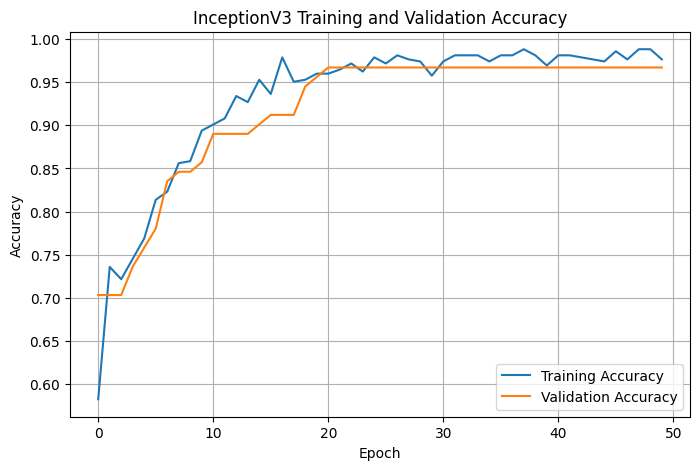

In [ ]:
# ============================================================
# CELL 17 — ACCURACY CURVE
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("InceptionV3 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

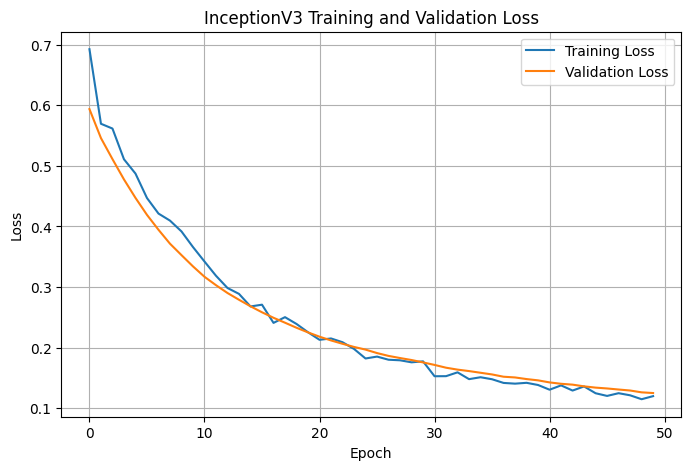

In [ ]:
# ============================================================
# CELL 18 — LOSS CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("InceptionV3 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# CELL 19 — LOAD BEST MODEL
# ============================================================

best_model = tf.keras.models.load_model(
    MODEL_PATH
)

print(" Best InceptionV3 model loaded.")
print("Model path:", MODEL_PATH)

 Best InceptionV3 model loaded.
Model path: /content/inceptionv3_sickle_best.keras


In [ ]:
# ============================================================
# CELL 20 — TEST SET EVALUATION
# ============================================================

print("==========================================")
print("        TEST SET EVALUATION")
print("==========================================")
print()

test_results = best_model.evaluate(
    test_ds,
    verbose=1
)

print()
print("Test Results:")
print("------------------------------------------")

for metric_name, value in zip(
    best_model.metrics_names,
    test_results
):
    print(f"{metric_name}: {value:.4f}")

        TEST SET EVALUATION

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 153ms/step - accuracy: 0.9670 - auc: 1.0000 - loss: 0.1992 - precision: 0.9545 - recall: 1.0000

Test Results:
------------------------------------------
loss: 0.1992
compile_metrics: 0.9670


In [ ]:
# ============================================================
# CELL 21 — FINAL CLASSIFICATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_true = []
y_prob = []

# Get predictions
for images, labels in test_ds:

    probabilities = best_model.predict(
        images,
        verbose=0
    ).ravel()

    y_prob.extend(probabilities)
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert probability → class
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc = roc_auc_score(
    y_true,
    y_prob
)

print("==========================================")
print("       INCEPTIONV3 FINAL RESULTS")
print("==========================================")
print()

print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-Score  : {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC   : {auc:.4f} ({auc*100:.2f}%)")

       INCEPTIONV3 FINAL RESULTS

Accuracy  : 0.9670 (96.70%)
Precision : 0.9545 (95.45%)
Recall    : 1.0000 (100.00%)
F1-Score  : 0.9767 (97.67%)
ROC-AUC   : 1.0000 (100.00%)


In [ ]:
# ============================================================
# CELL 22 — CLASSIFICATION REPORT
# ============================================================

print("==========================================")
print("       CLASSIFICATION REPORT")
print("==========================================")
print()

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Negative",
            "Positive"
        ],
        zero_division=0
    )
)

       CLASSIFICATION REPORT

              precision    recall  f1-score   support

    Negative       1.00      0.89      0.94        28
    Positive       0.95      1.00      0.98        63

    accuracy                           0.97        91
   macro avg       0.98      0.95      0.96        91
weighted avg       0.97      0.97      0.97        91



Confusion Matrix:
[[25  3]
 [ 0 63]]


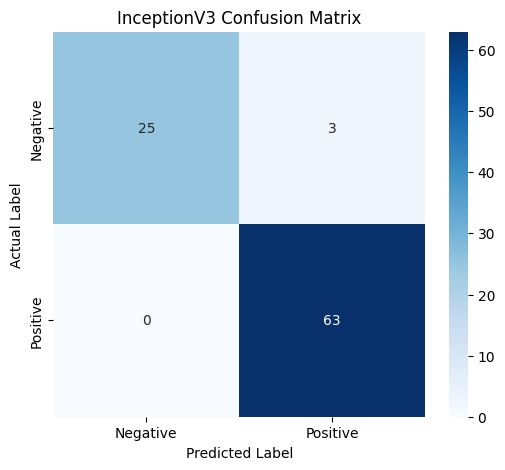

In [ ]:
# ============================================================
# CELL 23 — CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("InceptionV3 Confusion Matrix")

plt.show()

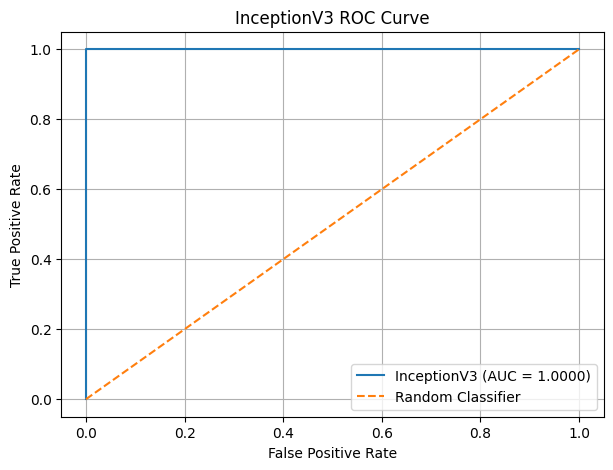

In [ ]:
# ============================================================
# CELL 24 — ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"InceptionV3 (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("InceptionV3 ROC Curve")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# CELL 25 — RESULTS TABLE
# ============================================================

results_table = pd.DataFrame({
    "Model": ["InceptionV3"],
    "Accuracy (%)": [accuracy * 100],
    "Precision (%)": [precision * 100],
    "Recall (%)": [recall * 100],
    "F1-Score (%)": [f1 * 100],
    "ROC-AUC (%)": [auc * 100]
})

results_table = results_table.round(2)

print(results_table.to_string(index=False))

      Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  ROC-AUC (%)
InceptionV3          96.7          95.45       100.0         97.67        100.0
